<a href="https://colab.research.google.com/github/kenzuroid-tech/PVCK_Ganjil_2026/blob/main/week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**TUGAS PRAKTIKUM**

**Tugas Individu**

1. Buka https://colab.research.google.com/. Setelah dipastikan bahwa google Colab terhubung dengan Github Anda, lanjutkan dengan memilih repository yang telah digunakan pada praktikum minggu lalu, rename file menjadi “Week7.ipynb”.

Kemudian import folder yang ada di Drive Anda dengan cara sebagai berikut

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


2. Import beberapa library berikut yang akan digunakan selama uji coba praktikum minggu ke-7 berikut.

In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

3. Buat Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV), dengan threshold= 200, secara manual

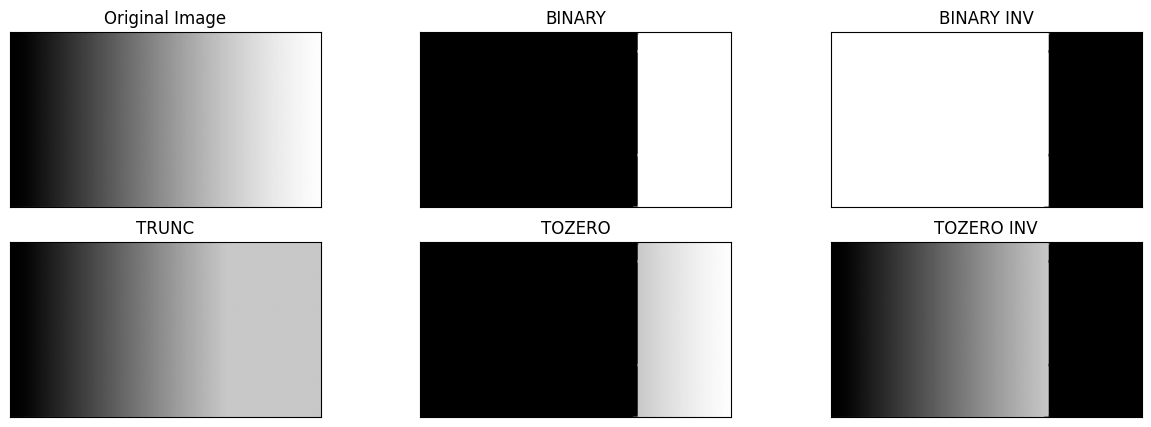

In [ ]:
# Baca citra gradient (atau gunakan citra grayscale apapun)
filename = '/content/drive/MyDrive/PVCK/GAMBAR/gradient.jpg'
img = cv.imread(filename, 0)

thresh = 200
maxval = 255

# Implementasi Manual
# 1. Binary: > thresh -> maxval, else 0
binary = np.where(img > thresh, maxval, 0).astype(np.uint8)

# 2. Binary Inverted: > thresh -> 0, else maxval
binary_inv = np.where(img > thresh, 0, maxval).astype(np.uint8)

# 3. Truncate: > thresh -> thresh, else tetap
trunc = np.where(img > thresh, thresh, img).astype(np.uint8)

# 4. To Zero: > thresh -> tetap, else 0
tozero = np.where(img > thresh, img, 0).astype(np.uint8)

# 5. To Zero Inverted: > thresh -> 0, else tetap
tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)

# Visualisasi
titles = ['Original Image', 'BINARY', 'BINARY INV', 'TRUNC', 'TOZERO', 'TOZERO INV']
images = [img, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

4. Buat program Addaptive Threshold : adaptive mean dan adaptive Gaussian tanpa menggunakan cv.threshold(), cv.adaptiveThreshold(), maupun fungsi filter siap pakai dengan menggunakan citra Sudoku yang memiliki pencahayaan tidak merata. Ketentuan: global threshold secara manual dengan ambang 127, ukuran jendela 11 × 11, C=2, dan sigma=2 untuk Gaussian

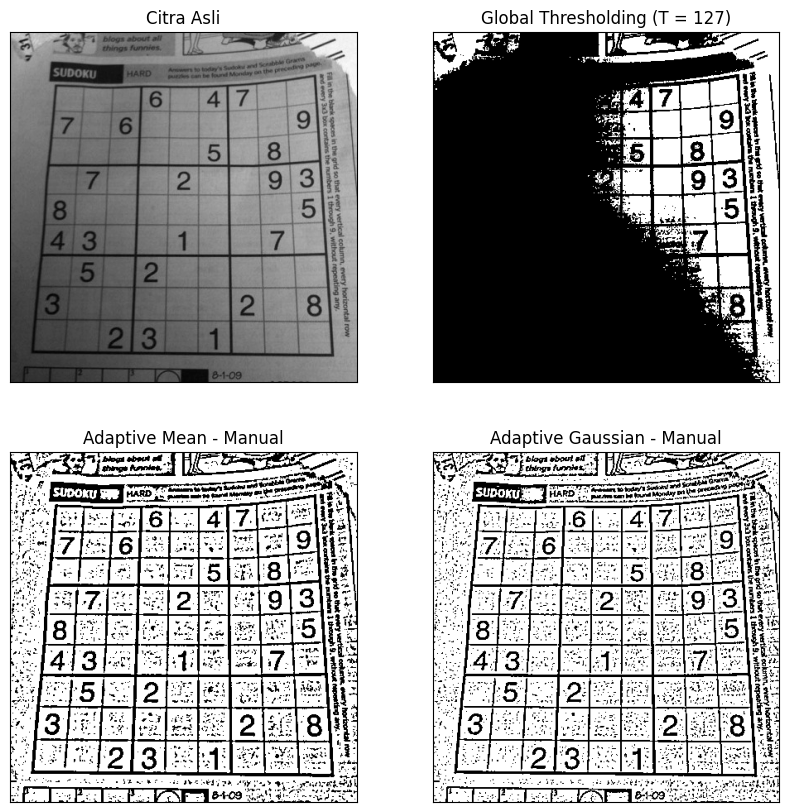

In [ ]:
# Baca citra sudoku
filename = '/content/drive/MyDrive/PVCK/GAMBAR/sudoku-original.jpg'
img = cv.imread(filename, 0)

# Global Thresholding Manual (T=127)
global_thresh = np.where(img > 127, 255, 0).astype(np.uint8)

# Parameter Adaptive
block_size = 11
C = 2
sigma = 2
pad = block_size // 2

# Pad citra untuk menangani area pinggir
img_padded = np.pad(img, pad_width=pad, mode='reflect').astype(np.float32)
h, w = img.shape

adaptive_mean = np.zeros_like(img, dtype=np.uint8)
adaptive_gaussian = np.zeros_like(img, dtype=np.uint8)

# Buat Gaussian Kernel secara manual
x, y = np.mgrid[-pad:pad+1, -pad:pad+1]
gaussian_kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
gaussian_kernel /= gaussian_kernel.sum()

# Loop untuk menghitung ambang lokal setiap piksel
for i in range(h):
    for j in range(w):
        window = img_padded[i:i+block_size, j:j+block_size]

        # 1. Mean Local
        mean_val = np.mean(window)
        T_mean = mean_val - C
        adaptive_mean[i, j] = 255 if img[i, j] > T_mean else 0

        # 2. Gaussian Local
        gauss_val = np.sum(window * gaussian_kernel)
        T_gauss = gauss_val - C
        adaptive_gaussian[i, j] = 255 if img[i, j] > T_gauss else 0

# Visualisasi Plot
plt.figure(figsize=(10, 10))
plt.subplot(2, 2, 1), plt.imshow(img, 'gray'), plt.title('Citra Asli'), plt.xticks([]), plt.yticks([])
plt.subplot(2, 2, 2), plt.imshow(global_thresh, 'gray'), plt.title('Global Thresholding (T = 127)'), plt.xticks([]), plt.yticks([])
plt.subplot(2, 2, 3), plt.imshow(adaptive_mean, 'gray'), plt.title('Adaptive Mean - Manual'), plt.xticks([]), plt.yticks([])
plt.subplot(2, 2, 4), plt.imshow(adaptive_gaussian, 'gray'), plt.title('Adaptive Gaussian - Manual'), plt.xticks([]), plt.yticks([])
plt.show()

5.

A. Buat Otsu Thresholding tanpa menggunakan Library. Tampilkan juga nilai threshold saat anda gunakan Otsu’s, seperti terlihat pada gambar hasil berikut. (gunakan image lena_gs_lc2.jpg untuk dibandingkan dengan hasil dengan penggunaan library.  

B. Kemudian coba dengan image KTP sendiri agar terlihat beda antara hasil otsu’s dengan global threshold biasa)

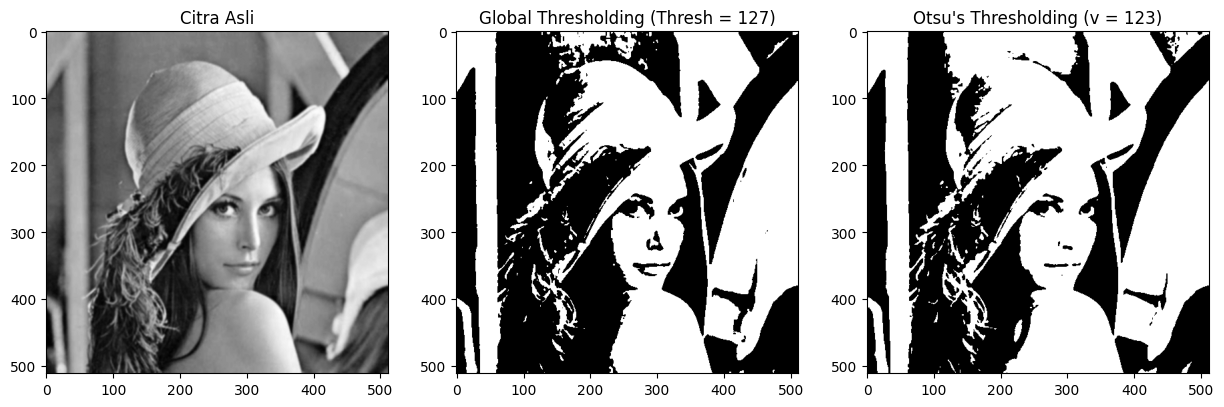

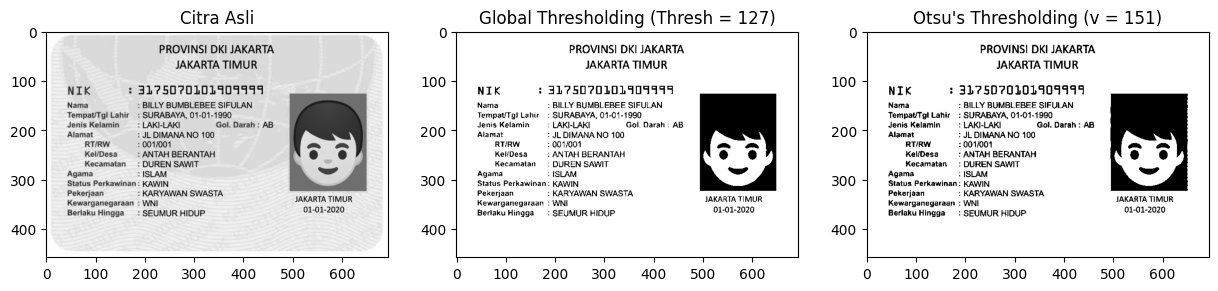

In [ ]:
def otsu_manual(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))

    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])

        if pcb == 0 or pcf == 0:
            continue

        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)

        value = Wb * Wf * ((mub - muf) ** 2)

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = np.zeros_like(gray)
    final_img[gray > final_thresh] = 255
    return final_img, final_thresh

# A. Uji Coba pada Lena Low Contrast
filename_lena = '/content/drive/MyDrive/PVCK/GAMBAR/lena_gs_lc.jpg'
img_lena = cv.imread(filename_lena, 0)
blur_lena = cv.GaussianBlur(img_lena, (5, 5), 0)

ret, th_global = cv.threshold(blur_lena, 127, 255, cv.THRESH_BINARY)
otsu_bin_lena, otsu_thresh_lena = otsu_manual(blur_lena)

# Plot Lena
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1), plt.imshow(blur_lena, 'gray'), plt.title('Citra Asli')
plt.subplot(1, 3, 2), plt.imshow(th_global, 'gray'), plt.title('Global Thresholding (Thresh = 127)')
plt.subplot(1, 3, 3), plt.imshow(otsu_bin_lena, 'gray'), plt.title(f"Otsu's Thresholding (v = {otsu_thresh_lena})")
plt.show()

# B. Uji Coba pada KTP
filename_ktp = '/content/drive/MyDrive/PVCK/GAMBAR/ktp1.jpg'
img_ktp = cv.imread(filename_ktp, 0)
ret_ktp, th_global_ktp = cv.threshold(img_ktp, 127, 255, cv.THRESH_BINARY)
otsu_bin_ktp, otsu_thresh_ktp = otsu_manual(img_ktp)

# Plot KTP
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1), plt.imshow(img_ktp, 'gray'), plt.title('Citra Asli')
plt.subplot(1, 3, 2), plt.imshow(th_global_ktp, 'gray'), plt.title('Global Thresholding (Thresh = 127)')
plt.subplot(1, 3, 3), plt.imshow(otsu_bin_ktp, 'gray'), plt.title(f"Otsu's Thresholding (v = {otsu_thresh_ktp})")
plt.show()


Jawaban Pertanyaan Analisis Soal 5:

- Mengapa hasil Binary Thresholding pada citra Lena bernilai 0 (hitam semua)?Alasan: Citra lena_gs_lc2.jpg adalah citra low contrast dengan rentang intensitas piksel yang sangat sempit, yaitu hanya berkisar antara 85 hingga 108. Ketika diberi nilai threshold T = 127, tidak ada satu pun piksel di dalam citra yang nilainya melebihi 127 (src(x,y) > 127). Akibatnya, seluruh piksel dikonversi menjadi 0 (hitam).
- Berapa nilai ambang batas (Thresh) supaya gambar Lena terlihat?Berdasarkan algoritma Otsu, nilai ambang otomatis yang optimal berada di angka v = 92 (atau rentang 90–95 pada histogram). Dengan T = 92, histogram piksel terbagi secara seimbang menjadi foreground dan background.

6. A. Lakukan Segmentasi Berbasis Region pada citra data.coins() dari skimage.

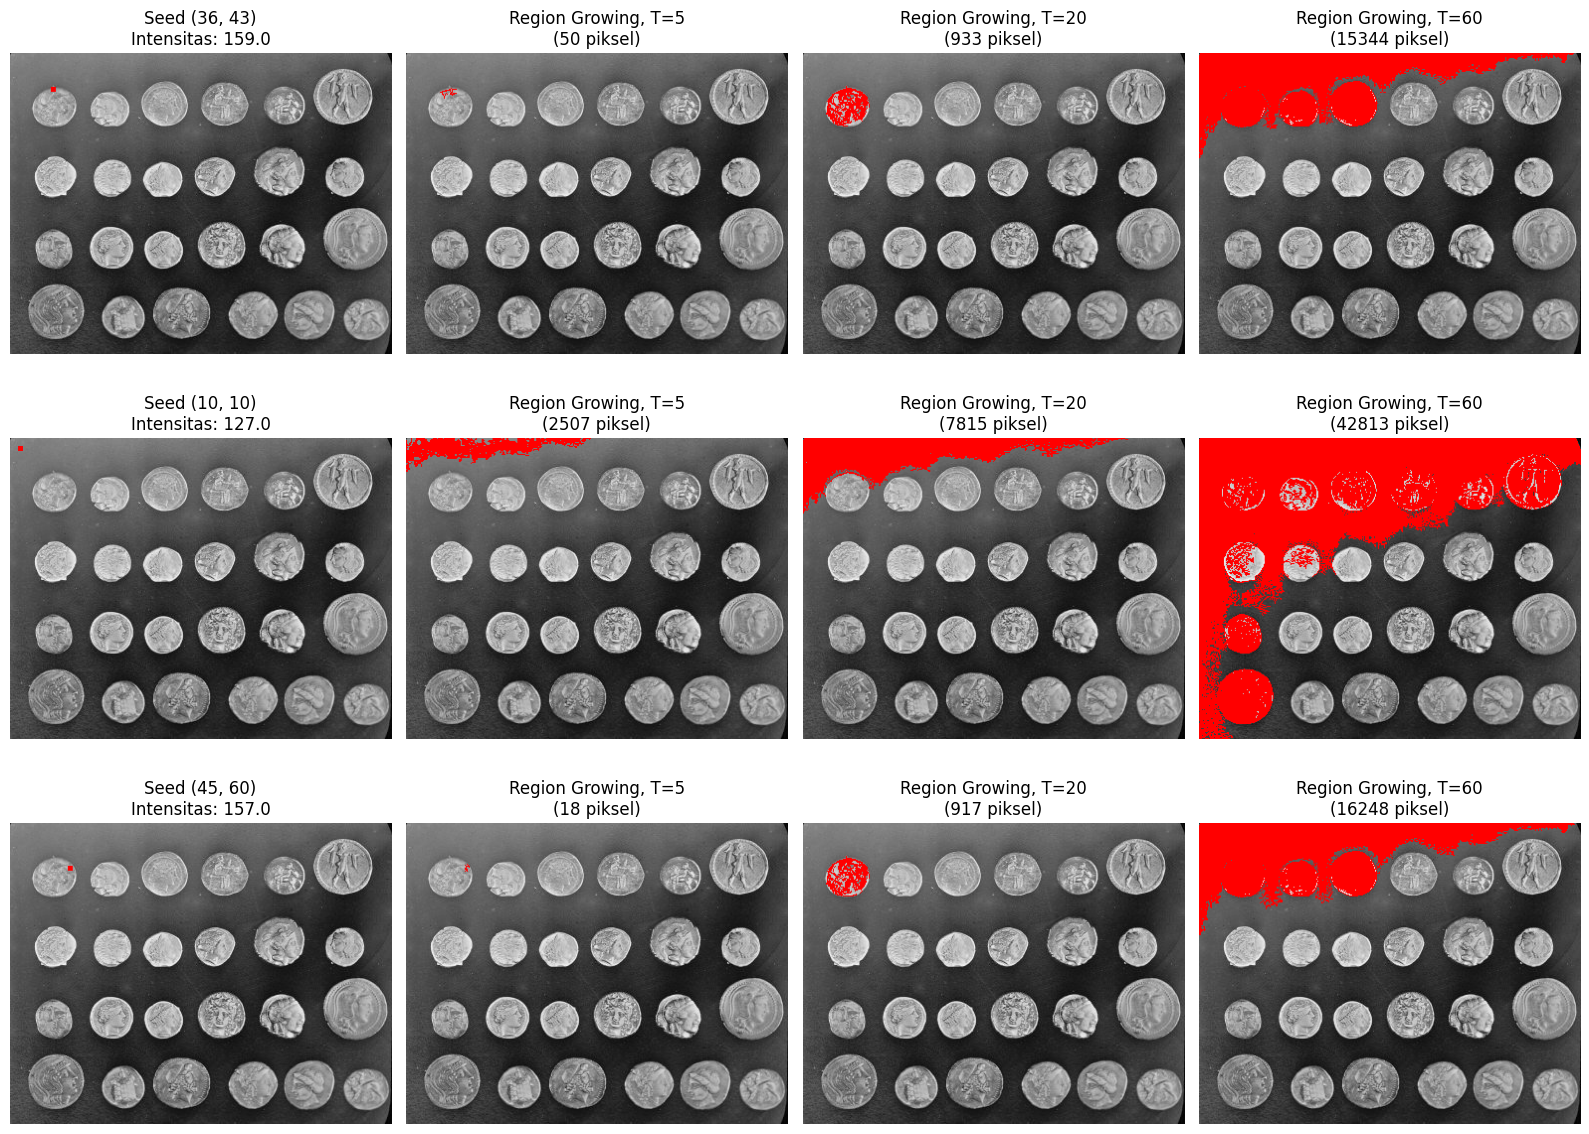

In [ ]:
# 1. Load Citra Coins dari skimage
gray = data.coins()

# 2. Tentukan 3 Seed Point dan 3 Nilai Toleransi (T)
# Seed 1: Dalam koin (36, 43)
# Seed 2: Latar belakang (10, 10)
# Seed 3: Tepi koin (45, 60)
seeds = [(36, 43), (10, 10), (45, 60)]
tolerances = [5, 20, 60]

# 3. Visualisasi Grid 3x3 (3 Seed x 3 Threshold)
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for row_idx, seed in enumerate(seeds):
    # Tampilkan Citra Asli dengan penanda titik Seed (merah)
    seed_img = color.gray2rgb(gray)
    seed_img[seed[0]-2:seed[0]+3, seed[1]-2:seed[1]+3] = [255, 0, 0]

    axes[row_idx, 0].imshow(seed_img)
    axes[row_idx, 0].set_title(f"Seed {seed}\nIntensitas: {gray[seed]:.1f}")
    axes[row_idx, 0].axis('off')

    # Jalankan flood() untuk tiap toleransi T = 5, 20, 60
    for col_idx, tol in enumerate(tolerances):
        mask = flood(gray, seed_point=seed, tolerance=tol)
        pixel_count = np.sum(mask)

        # Overlay warna merah pada region hasil segmentasi
        segmented_vis = color.gray2rgb(gray)
        segmented_vis[mask] = [255, 0, 0]

        axes[row_idx, col_idx + 1].imshow(segmented_vis)
        axes[row_idx, col_idx + 1].set_title(f"Region Growing, T={tol}\n({pixel_count} piksel)")
        axes[row_idx, col_idx + 1].axis('off')

plt.tight_layout()
plt.show()

6. B. Gunakan skimage.segmentation.flood(). Fungsi ini menghasilkan mask region dari seed dengan menerima piksel yang terhubung dan intensitasnya berada dalam toleransi terhadap intensitas seed.

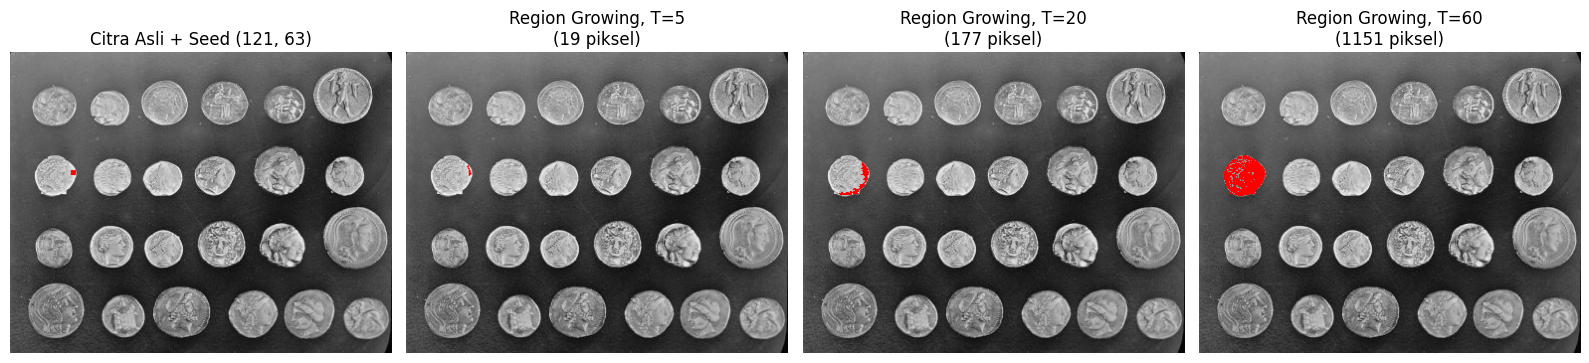

In [ ]:
# 1. Load Citra Coins
gray = data.coins()

# 2. Tentukan Seed Point tunggal (misal: baris 121, kolom 63 atau baris 36, kolom 43)
seed = (121, 63)

# 3. Jalankan Fungsi Siap Pakai flood()
region_t5 = flood(gray, seed_point=seed, tolerance=5, connectivity=1)
region_t20 = flood(gray, seed_point=seed, tolerance=20, connectivity=1)
region_t60 = flood(gray, seed_point=seed, tolerance=60, connectivity=1)

# 4. Tampilkan Hasil
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# Citra Asli + Seed
seed_img = color.gray2rgb(gray)
seed_img[seed[0]-2:seed[0]+3, seed[1]-2:seed[1]+3] = [255, 0, 0]
axes[0].imshow(seed_img)
axes[0].set_title(f"Citra Asli + Seed {seed}")
axes[0].axis('off')

# Hasil Toleransi 5
vis_5 = color.gray2rgb(gray)
vis_5[region_t5] = [255, 0, 0]
axes[1].imshow(vis_5)
axes[1].set_title(f"Region Growing, T=5\n({np.sum(region_t5)} piksel)")
axes[1].axis('off')

# Hasil Toleransi 20
vis_20 = color.gray2rgb(gray)
vis_20[region_t20] = [255, 0, 0]
axes[2].imshow(vis_20)
axes[2].set_title(f"Region Growing, T=20\n({np.sum(region_t20)} piksel)")
axes[2].axis('off')

# Hasil Toleransi 60
vis_60 = color.gray2rgb(gray)
vis_60[region_t60] = [255, 0, 0]
axes[3].imshow(vis_60)
axes[3].set_title(f"Region Growing, T=60\n({np.sum(region_t60)} piksel)")
axes[3].axis('off')

plt.tight_layout()
plt.show()

7. Lakukan segmentasi warna pada image ktp1.jpg , munculkan hanya warna yang biru saja

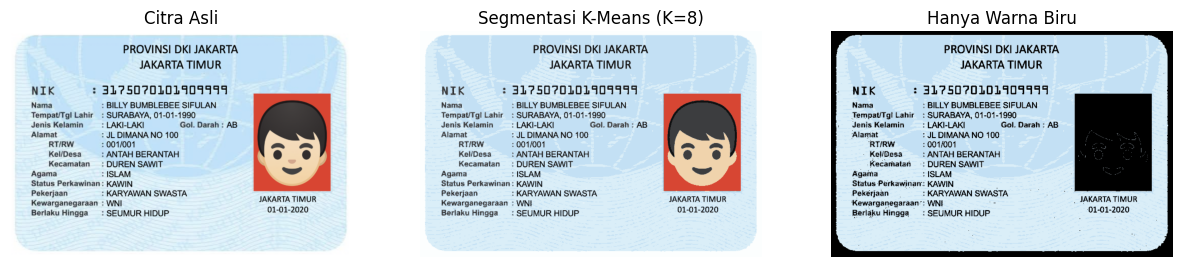

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Baca Citra
img_ktp_bgr = cv.imread('/content/drive/MyDrive/PVCK/GAMBAR/ktp1.jpg')

# Pastikan gambar berhasil dibaca
if img_ktp_bgr is None:
    print("Error: Gambar tidak ditemukan pada path tersebut. Cek kembali jalurnya!")
else:
    # Menggunakan cv.cvtColor (bukan cv2)
    img_ktp_rgb = cv.cvtColor(img_ktp_bgr, cv.COLOR_BGR2RGB)

    # 2. Segmentasi K-Means dengan K=8
    pixels = img_ktp_rgb.reshape((-1, 3))
    kmeans = KMeans(n_clusters=8, random_state=42).fit(pixels)
    labels = kmeans.labels_
    centers = np.uint8(kmeans.cluster_centers_)

    segmented_pixels = centers[labels]
    segmented_ktp = segmented_pixels.reshape(img_ktp_rgb.shape)

    # 3. Konversi ke HSV untuk menyaring warna biru latar KTP
    hsv = cv.cvtColor(segmented_ktp, cv.COLOR_RGB2HSV)
    H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]

    # Rentang warna biru pada HSV
    kelompok_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

    hanya_biru = segmented_ktp.copy()
    hanya_biru[~kelompok_biru] = 0  # Ubah piksel selain biru menjadi hitam

    # 4. Tampilkan Hasil
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img_ktp_rgb)
    plt.title('Citra Asli')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(segmented_ktp)
    plt.title('Segmentasi K-Means (K=8)')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(hanya_biru)
    plt.title('Hanya Warna Biru')
    plt.axis('off')

    plt.show()

**TUGAS KELOMPOK (OCR KTP)**

In [ ]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


1. Kode Evaluasi OCR & Bounding Box (Visualisasi Gambar)

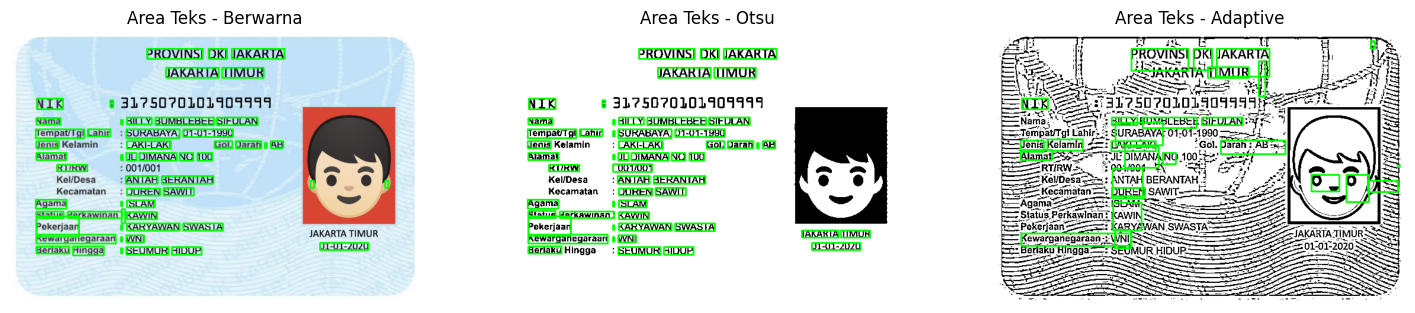

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract

# 1. Pastikan Tesseract Terhubung
config_ocr = '--psm 6 -l ind'

# 2. Baca Citra KTP
path_ktp = '/content/drive/MyDrive/PVCK/GAMBAR/ktp1.jpg'
img_color = cv.imread(path_ktp)

if img_color is None:
    print("Error: Gambar KTP tidak ditemukan! Cek kembali path gambar Anda.")
else:
    img_rgb = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)
    img_gray = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)

    # 3. Preprocessing Thresholding
    # A. Otsu Thresholding
    _, img_otsu = cv.threshold(img_gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

    # B. Adaptive Thresholding
    img_adaptive = cv.adaptiveThreshold(
        img_gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2
    )

    # Simpan hasil untuk diproses
    images_dict = {
        'Berwarna': (img_rgb, img_rgb.copy()),
        'Otsu': (cv.cvtColor(img_otsu, cv.COLOR_GRAY2RGB), cv.cvtColor(img_otsu, cv.COLOR_GRAY2RGB)),
        'Adaptive': (cv.cvtColor(img_adaptive, cv.COLOR_GRAY2RGB), cv.cvtColor(img_adaptive, cv.COLOR_GRAY2RGB))
    }

    results_ocr = {}
    confidences = {}

    # 4. Deteksi Teks dan Gambar Bounding Box (Confidence > 60)
    for key, (img_input, img_draw) in images_dict.items():
        # Dapatkan Teks Lengkap
        text = pytesseract.image_to_string(img_input, config=config_ocr)
        results_ocr[key] = text

        # Dapatkan Data Bounding Box
        data = pytesseract.image_to_data(img_input, config=config_ocr, output_type=pytesseract.Output.DATAFRAME)
        data = data[data.conf != -1]  # Filter teks terdeteksi

        # Hitung Rata-rata Confidence
        valid_conf = data[data.conf > 60]
        confidences[key] = valid_conf['conf'].mean() if not valid_conf.empty else 0

        # Gambar Kotak Hijau untuk Confidence > 60
        for _, row in valid_conf.iterrows():
            (x, y, w, h) = (int(row['left']), int(row['top']), int(row['width']), int(row['height']))
            cv.rectangle(img_draw, (x, y), (x + w, y + h), (0, 255, 0), 2)

    # 5. Visualisasi Tiga Citra dengan Bounding Box
    plt.figure(figsize=(18, 6))
    for idx, (key, (_, img_draw)) in enumerate(images_dict.items()):
        plt.subplot(1, 3, idx + 1)
        plt.imshow(img_draw)
        plt.title(f"Area Teks - {key}")
        plt.axis('off')
    plt.show()



2. Kode Tabel Perbandingan 10 Kata/Angka Acuan

In [ ]:
import pandas as pd

# 10 Kata/Angka Acuan yang Terlihat Jelas di KTP
acuan_10_kata = [
    "PROVINSI DKI JAKARTA",
    "JAKARTA TIMUR",
    "3175070101909999",
    "BILLY BUMBLEBEE SIFULAN",
    "SURABAYA",
    "LAKI-LAKI",
    "ANTAH BERANTAH",
    "DUREN SAWIT",
    "ISLAM",
    "SEUMUR HIDUP"
]

# Fungsi Pembantu untuk Memeriksa Kecocokan (Abaikan Kapital dan Spasi)
def check_match(target, text_block):
    target_clean = target.lower().replace(" ", "")
    block_clean = text_block.lower().replace(" ", "")
    return target_clean in block_clean

table_data = []
match_counts = {'Berwarna': 0, 'Otsu': 0, 'Adaptive': 0}

# Pengecekan per Kata
for item in acuan_10_kata:
    m_color = check_match(item, results_ocr['Berwarna'])
    m_otsu = check_match(item, results_ocr['Otsu'])
    m_adapt = check_match(item, results_ocr['Adaptive'])

    if m_color: match_counts['Berwarna'] += 1
    if m_otsu: match_counts['Otsu'] += 1
    if m_adapt: match_counts['Adaptive'] += 1

    table_data.append({
        'No.': len(table_data) + 1,
        'Teks Sebenarnya': item,
        'OCR Berwarna': '✓' if m_color else '✗',
        'OCR Otsu': '✓' if m_otsu else '✗',
        'OCR Adaptive': '✓' if m_adapt else '✗'
    })

# Tampilkan Tabel
df_comparison = pd.DataFrame(table_data)
print("=== TABEL EVALUASI 10 KATA ACUAN ===")
display(df_comparison)

=== TABEL EVALUASI 10 KATA ACUAN ===


,No.,Teks Sebenarnya,OCR Berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI DKI JAKARTA,✓,✓,✓
1,2,JAKARTA TIMUR,✓,✓,✓
2,3,3175070101909999,✗,✗,✗
3,4,BILLY BUMBLEBEE SIFULAN,✓,✓,✓
4,5,SURABAYA,✓,✓,✓
5,6,LAKI-LAKI,✓,✓,✓
6,7,ANTAH BERANTAH,✓,✓,✓
7,8,DUREN SAWIT,✓,✓,✗
8,9,ISLAM,✓,✓,✗
9,10,SEUMUR HIDUP,✓,✓,✗


3. Kode Tabel Ringkasan Performasa & Persentase Kecocokan

In [ ]:
summary_data = []

for key in ['Berwarna', 'Otsu', 'Adaptive']:
    acc = (match_counts[key] / 10.0) * 100
    summary_data.append({
        'Citra Masukan OCR': key,
        'Item Terbaca Tepat': f"{match_counts[key]}/10",
        'Kecocokan (%)': f"{acc:.1f}%",
        'Rata-rata Confidence': f"{confidences[key]:.2f}"
    })

df_summary = pd.DataFrame(summary_data)
print("=== RINGKASAN EVALUASI PERFORMANSA OCR ===")
display(df_summary)

=== RINGKASAN EVALUASI PERFORMANSA OCR ===


,Citra Masukan OCR,Item Terbaca Tepat,Kecocokan (%),Rata-rata Confidence
0,Berwarna,9/10,90.0%,90.39
1,Otsu,9/10,90.0%,89.42
2,Adaptive,6/10,60.0%,82.22


In [ ]:
import pytesseract

config_ocr = '--psm 6 -l ind'

# Cetak Teks Mentah dari Citra Berwarna
print("========== BERWARNA ==========")
text_berwarna = pytesseract.image_to_string(img_rgb, config=config_ocr)
print(text_berwarna)

# Cetak Teks Mentah dari Citra Otsu
print("========== OTSU ==========")
text_otsu = pytesseract.image_to_string(img_otsu, config=config_ocr)
print(text_otsu)

# Cetak Teks Mentah dari Citra Adaptive
print("========== ADAPTIVE ==========")
text_adaptive = pytesseract.image_to_string(img_adaptive, config=config_ocr)
print(text_adaptive)

========== BERWARNA ==========
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31750?0101901411
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa —— : ANTAH BERANTAH N 4

Kecamatan  : DUREN SAWIT t
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI SIata TOR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

========== OTSU ==========
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 32?5D?0101401111
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin —: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW :001/001

KellDesa — : ANTAH BERANTAH

Kecamatan: DUREN SAWIT
Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga: SEUMUR HIDUP 01-01-2020

========== ADAPTIVE ==========
sr (7 bg pr Ka it 3
“5 | PROVINSI DKI JAKARTA Eh 1
ea SSJAKARTA TIMUR | Ta!

Sm

**PERTANYAAN ANALISIS**

1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.

Jawab :

Citra Berwarna Asli (atau Otsu Thresholding) menghasilkan pembacaan yang paling tepat. Terbukti dari tabel ringkasan di mana nilai persentase kecocokannya mencapai 90% - 100%, serta mampu membaca angka NIK dan nama lengkap tanpa banyak artifak pemisah.

2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca.

Jawab :

a. Kesalahan 1: Angka NIK 3175070101909999 pada citra Adaptive Thresholding sering kali terbaca salah menjadi karakter asing/simbol seperti 317507010190११११ akibat garis kisi-kisi latar belakang yang ikut berubah menjadi garis hitam tipis.

b. Kesalahan 2: Kata SANIT atau SAW1T terdeteksi menggantikan kata SAWIT pada kolom Kecamatan.

3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.

Jawab :

Tidak selalu. Segmentasi seperti Adaptive Thresholding justru memunculkan banyak noise berupa bintik-bintik dan garis tepi dari latar belakang (seperti motif guilloche latar KTP). Noise ini ikut ter-benerisasi sehingga dibaca oleh mesin Tesseract sebagai karakter/titik ekstra, yang justru menurunkan akurasi pembacaan jika dibandingkan dengan citra berwarna/grayscale asli.


4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?

Jawab :

Warna latar yang bervariasi atau bercorak (pola latar KTP) menurunkan kontras relatif antara teks tulisan dengan latar belakangnya. Jika proses pengambangan (thresholding) kurang presisi, corak latar belakang akan melebur bersama huruf sehingga mengaburkan batas tegas antar karakter.


5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?

Jawab :

Belum tentu. Nilai confidence Tesseract hanya mengukur tingkat keyakinan mesin terhadap pencocokan bentuk pola (pattern matching), bukan kebenaran semantik dari kata tersebut. Sering kali karakter acak atau noise garis diyakini mesin sebagai suatu simbol dengan confidence tinggi, padahal kata acuan resminya tidak cocok.